# Séparation par photo d'origine et jeu de test

Dans `pretrained_cnn_model.ipynb`, le dossier `dataset/` contient 250 photos d'origine et 5 variantes augmentées de chacune (`aug_bright_`, `aug_flip_`, `aug_noise_`, `aug_rot_`, `aug_zoom_`), soit 1 500 images. La séparation 80/20 se fait sur ces 1 500 images : les variantes d'une même photo tombent des deux côtés. La validation (83 %) mesure donc en partie des photos que le modèle a déjà vues.

Ce notebook garde **le même modèle et la même recette** (ResNet50 gelé puis fine-tuning des 30 dernières couches, mêmes hyperparamètres). Une seule chose change, la séparation :

1. chaque variante augmentée est rattachée à sa photo d'origine ;
2. les photos d'origine presque identiques sont regroupées ;
3. la séparation se fait **par groupe**, avant toute augmentation : 70 % entraînement, 15 % validation, 15 % test, par espèce ;
4. les variantes augmentées ne vont qu'en entraînement ; validation et test ne contiennent que des photos d'origine ;
5. le test ne sert qu'une fois, à la fin.

Les données ne sont pas distribuées : les photos viennent du web, avec des droits inconnus. Pour rejouer le notebook, placez vos images dans `dataset/<espèce>/`, avec les variantes `aug_<type>_<photo>` si vous reproduisez la recette d'origine.

In [1]:
import os, re, json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Input, Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import Sequential, layers

dataset_path = "dataset"
seed = 12  # Même graine que le notebook d'origine
batch_size = 16
img_size = (256, 256)
tf.keras.utils.set_random_seed(seed)

## 1. Rattacher chaque variante à sa photo d'origine

In [2]:
AUG = re.compile(r"^aug_(bright|flip|noise|rot|zoom)_")
class_names = sorted(d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d)))

files = []  # (classe, fichier, photo d'origine)
for c in class_names:
    for f in sorted(os.listdir(os.path.join(dataset_path, c))):
        files.append((c, f, AUG.sub("", f)))

originals = {(c, f) for c, f, src in files if f == src}
assert all((c, src) in originals for c, f, src in files), "une variante sans photo d'origine"
print(len(files), "images,", len(originals), "photos d'origine,", len(class_names), "espèces")

1500 images, 250 photos d'origine, 13 espèces


## 2. Regrouper les photos d'origine presque identiques

Le MD5 du notebook de modélisation ne retire que les copies exactes. Une même photo enregistrée en `.jpg` et en `.png`, ou recadrée, passe au travers. On compare une empreinte visuelle (dHash 64 bits) de chaque paire de photos d'origine : à 6 bits d'écart ou moins, elles vont dans le même groupe, donc du même côté de la séparation.

In [3]:
def dhash(path):
    g = np.asarray(Image.open(path).convert("L").resize((9, 8), Image.BILINEAR), dtype=np.int16)
    return (g[:, 1:] > g[:, :-1]).flatten()

orig = sorted(originals)
hashes = np.array([dhash(os.path.join(dataset_path, c, f)) for c, f in orig])
parent = list(range(len(orig)))
def root(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i

pairs = []
for i in range(len(orig)):
    d = (hashes[i + 1:] != hashes[i]).sum(axis=1)
    for j in np.flatnonzero(d <= 6) + i + 1:
        pairs.append((orig[i], orig[j], int(d[j - i - 1])))
        parent[root(j)] = root(i)

for a, b, d in pairs:
    print(f"{d:2d} bits  {a[0]}/{a[1]}  ~  {b[0]}/{b[1]}")
cross = [(a, b) for a, b, _ in pairs if a[0] != b[0]]
print(len(pairs), "paires presque identiques, dont", len(cross), "entre deux espèces différentes")
group = {o: root(i) for i, o in enumerate(orig)}

0 paires presque identiques, dont 0 entre deux espèces différentes


## 3. Séparer par groupe, espèce par espèce

In [4]:
rng = np.random.default_rng(seed)
split = {}
for c in class_names:
    groups = sorted({g for (cc, _), g in group.items() if cc == c})
    rng.shuffle(groups)
    n_test = max(1, round(len(groups) * 0.15))
    n_val = max(1, round(len(groups) * 0.15))
    for k, g in enumerate(groups):
        split.setdefault(g, "test" if k < n_test else "val" if k < n_test + n_val else "train")

sets = {"train": [], "val": [], "test": []}
for c, f, src in files:
    s = split[group[(c, src)]]
    if s == "train" or f == src:  # les variantes augmentées ne vont qu'en entraînement
        sets[s].append((os.path.join(dataset_path, c, f), class_names.index(c)))

# Contrôle : aucun groupe, donc aucune photo d'origine, de part et d'autre de la séparation
grp = {os.path.join(dataset_path, c, f): group[(c, src)] for c, f, src in files}
g = {s: {grp[p] for p, _ in items} for s, items in sets.items()}
assert not (g["train"] & g["val"] or g["train"] & g["test"] or g["val"] & g["test"])
for s, items in sets.items():
    print(f"{s:5s} {len(items):5d} images", np.bincount([y for _, y in items], minlength=len(class_names)))

train  1044 images [ 72  72  96  90  78  42  72  96  96  96  36 102  96]
val      38 images [2 3 4 3 3 2 3 4 3 3 2 3 3]
test     38 images [2 3 4 3 3 2 3 4 3 3 2 3 3]


In [5]:
def load(items):
    # Même redimensionnement que image_dataset_from_directory : bilinéaire, sans recadrage
    x = np.stack([np.asarray(Image.open(p).convert("RGB").resize(img_size, Image.BILINEAR), dtype=np.uint8) for p, _ in items])
    y = tf.keras.utils.to_categorical([lbl for _, lbl in items], len(class_names))
    return x, y

(x_train, y_train), (x_val, y_val), (x_test, y_test) = load(sets["train"]), load(sets["val"]), load(sets["test"])
to_float = lambda x, y: (tf.cast(x, tf.float32), y)  # pixels 0-255 en float, comme image_dataset_from_directory
train_ds = tf.data.Dataset.from_tensor_slices((x_train, y_train)).shuffle(len(x_train), seed=seed).batch(batch_size).map(to_float)
validation_ds = tf.data.Dataset.from_tensor_slices((x_val, y_val)).batch(batch_size).map(to_float)

## 4. Le même modèle que `pretrained_cnn_model.ipynb`

In [6]:
data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomBrightness(0.2),
    layers.GaussianNoise(0.05),
])

inputs = Input(shape=(256, 256, 3))
x = data_augmentation(inputs)
base_model = ResNet50(weights="imagenet", include_top=False, input_tensor=x)
base_model.trainable = False
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.5)(x)
x = Dense(128, activation="relu")(x)
x = Dropout(0.3)(x)
predictions = Dense(len(class_names), activation="softmax")(x)
model = Model(inputs=inputs, outputs=predictions)

early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
model.compile(optimizer=Adam(learning_rate=1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
history = model.fit(train_ds, validation_data=validation_ds, epochs=10, callbacks=[early_stop], verbose=2)

       0/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   16384/94765736 ━━━━━━━━━━━━━━━━━━━━ 8:00 5us/step

   49152/94765736 ━━━━━━━━━━━━━━━━━━━━ 5:37 4us/step

   81920/94765736 ━━━━━━━━━━━━━━━━━━━━ 5:19 3us/step

  131072/94765736 ━━━━━━━━━━━━━━━━━━━━ 3:58 3us/step

...

66/66 - 133s - 2s/step - accuracy: 0.6772 - loss: 0.9647 - val_accuracy: 0.2105 - val_loss: 3.1854


Epoch 9/10


66/66 - 145s - 2s/step - accuracy: 0.6791 - loss: 0.9941 - val_accuracy: 0.2895 - val_loss: 3.1161


Epoch 10/10


66/66 - 138s - 2s/step - accuracy: 0.7031 - loss: 0.8955 - val_accuracy: 0.2368 - val_loss: 3.3694


In [7]:
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
model.compile(optimizer=Adam(learning_rate=1e-5), loss="categorical_crossentropy", metrics=["accuracy"])
history_finetune = model.fit(train_ds, validation_data=validation_ds, epochs=20, callbacks=[early_stop], verbose=2)

Epoch 1/20


66/66 - 192s - 3s/step - accuracy: 0.2088 - loss: 2.3042 - val_accuracy: 0.1316 - val_loss: 2.5193


Epoch 2/20


66/66 - 184s - 3s/step - accuracy: 0.2759 - loss: 2.1715 - val_accuracy: 0.2105 - val_loss: 2.4657


Epoch 3/20


...

66/66 - 142s - 2s/step - accuracy: 0.6830 - loss: 1.0684 - val_accuracy: 0.2895 - val_loss: 2.6093


Epoch 15/20


66/66 - 143s - 2s/step - accuracy: 0.7126 - loss: 0.9735 - val_accuracy: 0.2632 - val_loss: 2.6494


Epoch 16/20


66/66 - 141s - 2s/step - accuracy: 0.7251 - loss: 0.9036 - val_accuracy: 0.2895 - val_loss: 2.6982


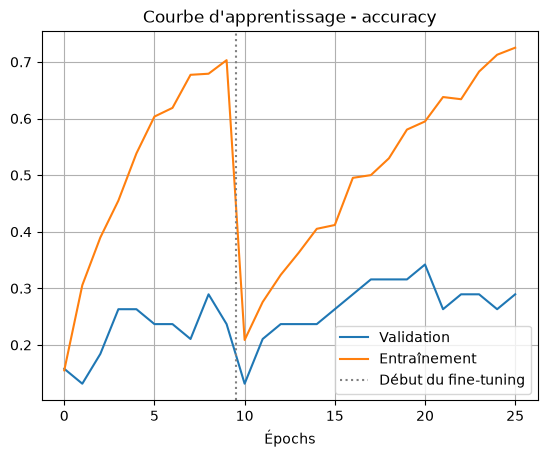

In [8]:
plt.plot(history.history["val_accuracy"] + history_finetune.history["val_accuracy"], label="Validation")
plt.plot(history.history["accuracy"] + history_finetune.history["accuracy"], label="Entraînement")
plt.axvline(len(history.history["accuracy"]) - 0.5, color="grey", ls=":", label="Début du fine-tuning")
plt.title("Courbe d'apprentissage - accuracy"); plt.xlabel("Épochs"); plt.legend(); plt.grid(True); plt.show()

## 5. Évaluation, une seule fois, sur le jeu de test

Le test est petit (une quarantaine de photos) : l'intervalle à 95 % est calculé par bootstrap, 2 000 tirages avec remise.

In [9]:
def evaluate(x, y):
    y_true = y.argmax(axis=1)
    y_pred = model.predict(x.astype("float32"), batch_size=batch_size, verbose=0).argmax(axis=1)
    return y_true, y_pred

def bootstrap(y_true, y_pred, metric, n=2000):
    r = np.random.default_rng(seed)
    idx = r.integers(0, len(y_true), (n, len(y_true)))
    vals = [metric(y_true[i], y_pred[i]) for i in idx]
    return np.percentile(vals, [2.5, 97.5])

macro_f1 = lambda t, p: f1_score(t, p, average="macro", labels=range(len(class_names)), zero_division=0)
results = {}
for name, (x, y) in {"validation": (x_val, y_val), "test": (x_test, y_test)}.items():
    t, p = evaluate(x, y)
    results[name] = dict(n=len(t), accuracy=accuracy_score(t, p), f1_macro=macro_f1(t, p),
                         accuracy_ic95=bootstrap(t, p, accuracy_score).tolist(), f1_macro_ic95=bootstrap(t, p, macro_f1).tolist())
    print(f"{name:10s} n={len(t):3d}  accuracy {results[name]['accuracy']:.3f} {np.round(results[name]['accuracy_ic95'], 3)}"
          f"  F1 macro {results[name]['f1_macro']:.3f} {np.round(results[name]['f1_macro_ic95'], 3)}")
y_true, y_pred = t, p  # test

validation n= 38  accuracy 0.263 [0.132 0.421]  F1 macro 0.232 [0.095 0.317]


test       n= 38  accuracy 0.263 [0.132 0.395]  F1 macro 0.256 [0.113 0.331]


              precision    recall  f1-score   support

      Castor       0.25      0.50      0.33         2
        Chat       0.00      0.00      0.00         3
       Chien       0.33      0.25      0.29         4
      Coyote       0.00      0.00      0.00         3
    Ecureuil       0.50      0.33      0.40         3
       Lapin       0.00      0.00      0.00         2
        Loup       0.00      0.00      0.00         3
        Lynx       0.12      0.25      0.17         4
        Ours       0.00      0.00      0.00         3
        Puma       0.25      0.33      0.29         3
         Rat       1.00      1.00      1.00         2
Raton laveur       0.50      0.67      0.57         3
      Renard       0.25      0.33      0.29         3

    accuracy                           0.26        38
   macro avg       0.25      0.28      0.26        38
weighted avg       0.23      0.26      0.24        38



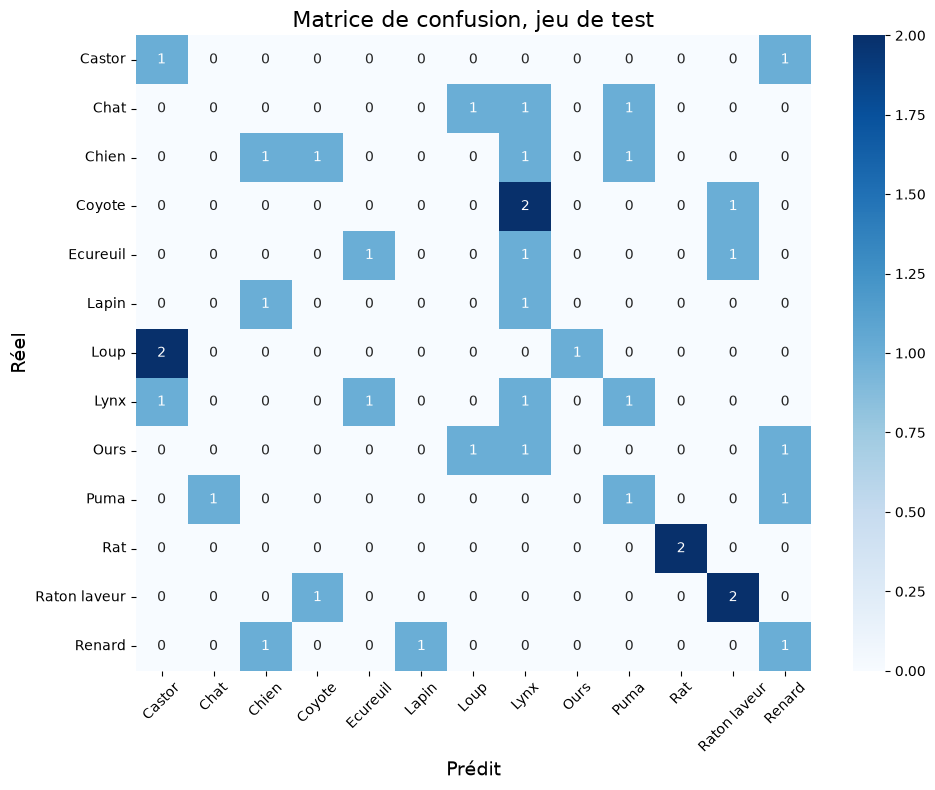

In [10]:
print(classification_report(y_true, y_pred, labels=range(len(class_names)), target_names=class_names, zero_division=0))
cm = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prédit", fontsize=14); plt.ylabel("Réel", fontsize=14)
plt.title("Matrice de confusion, jeu de test", fontsize=16)
plt.xticks(rotation=45); plt.yticks(rotation=0); plt.tight_layout(); plt.show()
with open("resultats_split_par_photo.json", "w") as f:
    json.dump(results, f, indent=2)

## Conclusion

Sur un jeu de test jamais vu (38 photos d'origine), le modèle donne **26 %** de bonnes réponses (intervalle à 95 % : 13 % à 39 %) et un F1 macro de 0.26 (0.11 à 0.33). Au hasard, sur 13 espèces, on aurait 8 %.

Les 83 % de `pretrained_cnn_model.ipynb` venaient donc surtout de la fuite : le modèle reconnaissait des variantes de photos qu'il avait déjà vues. Aucune paire de photos d'origine presque identiques n'a été trouvée : la fuite venait seulement de l'augmentation faite avant la séparation.

Les courbes vont dans le même sens : l'exactitude monte vers 70 % en entraînement et ne dépasse jamais 35 % en validation. Avec moins de 20 photos par espèce, le modèle retient les photos plutôt que les empreintes.

Pistes, à tester une par une et toujours mesurées sur la validation, jamais sur le test :
- `tf.keras.applications.resnet50.preprocess_input` : ResNet50 attend des images centrées sur la moyenne d'ImageNet, et le modèle actuel reçoit des pixels bruts de 0 à 255 (testé dans `split_par_photo_preprocess.ipynb`) ;
- une validation croisée par groupes (`StratifiedGroupKFold`), plus stable qu'un seul petit jeu de test ;
- plus de photos d'origine, surtout pour les espèces les plus rares (Rat : 10, Lapin : 11).